# Semana del 22 · política random con visión local de 5×5

**Política que recoge los datos: RANDOM UNIFORME durante todo el entrenamiento.** Las acciones izquierda, derecha y avanzar se eligen con probabilidad 1/3 cada una, independientemente de lo que proponga el actor. Se configura de forma explícita `trainer.random_policy=True`.

**Qué aprende.** El modelo del mundo, el actor y el crítico se entrenan usando esos datos (`model.train_actor_critic=True`). En las evaluaciones y en el video final juega el **actor aprendido**. La pregunta es si ese actor aprende a conseguir galletas a partir de experiencias recogidas al azar.

**Cuatro casos comparables.** Visión completa, 3×3, 5×5 y 7×7. Solo cambia la observación: mapa de pasillos cortos, 500.000 pasos, semilla 0, decoder Dreamer, imagen 64×64, `TRAIN_RATIO = 128`, buffer de 500.000 en RAM, muestreo uniforme del buffer (`reward_slices=0`), entropía original (`act_entropy=0.0003`) y evaluación cada 25.000 pasos con 5 partidas.

**Carpetas nuevas.** Este run guarda en `galleta/semana22/`, con sufijo `_random`; empieza desde cero la primera vez y retoma su propio checkpoint al repetirlo. Los resultados anteriores permanecen en sus carpetas originales.

**Comprobación antes de entrenar.** La sección 6 imprime `trainer.random_policy=True`. La prueba corta y la sección 10 comprueban además la configuración efectiva de Hydra y rechazan un `False` o una carpeta con configuración incompatible antes de iniciar el entrenamiento.

**Qué resultado mirar.** `episode/eval_score` mide las galletas del actor aprendido. `episode/score` mide las del recolector al azar: no permite concluir que el actor haya aprendido. El gráfico de la sección 11 muestra las evaluaciones del actor.

**Primera vez:** selecciona L4 GPU y ejecuta las secciones 1 a 10 en orden. La prueba corta verifica el entorno antes del run largo. Cada notebook necesita su propio entorno si se ejecutan a la vez. La primera velocidad medida permite estimar el tiempo; no hay garantía de que aprenda en 500.000 pasos.

**Para continuar:** secciones 1 a 6 y 10. **Para leer resultados en CPU:** secciones 2, 3, 6 y 11. Con `APAGAR_AL_TERMINAR = True` se guarda todo, se sincroniza Drive y se libera la sesión al terminar correctamente. Para ver resultados después del apagado, vuelve a conectar una sesión.


## 1. Revisar la GPU y la RAM

In [1]:
!nvidia-smi --query-gpu=name,memory.total --format=csv,noheader
import os

ram = os.sysconf("SC_PAGE_SIZE") * os.sysconf("SC_PHYS_PAGES") / 1e9
print(f"RAM: {ram:.0f} GB")
if ram < 20:
    print("OJO: el buffer de este run ocupa ~11 GB de RAM. Usa la L4 (viene con 53 GB) o activa High-RAM.")

NVIDIA L4, 23034 MiB
RAM: 57 GB


## 2. Montar Drive

Aquí quedan el checkpoint, el buffer y las métricas, para que sobrevivan al corte de sesión.

In [2]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


## 3. Clonar el repo (o actualizarlo si ya está)

In [3]:
%%bash
if [ -d /content/r2dreamer-cookie ]; then
  cd /content/r2dreamer-cookie && git pull --ff-only
else
  git clone https://github.com/FabriRandon/r2dreamer-cookie.git /content/r2dreamer-cookie
fi

Cloning into '/content/r2dreamer-cookie'...


## 4. Instalar

r2dreamer necesita Python 3.11 y Colab suele traer una versión más nueva, así que se crea un entorno aparte con `uv`. Toma unos minutos y hay que repetirlo en cada sesión nueva.

In [4]:
%%bash
pip install -q uv
cd /content/r2dreamer-cookie
uv venv --python 3.11 .venv
uv pip install --python .venv/bin/python -e ".[cookie]" 2>&1 | tail -3

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 129.0 MB/s eta 0:00:00
 + urllib3==2.8.0
 + werkzeug==3.1.9
 + zipp==4.1.2


Using CPython 3.11.17
Creating virtual environment at: .venv
Activate with: source .venv/bin/activate


## 5. Comprobar que todo quedó bien

In [5]:
%%bash
cd /content/r2dreamer-cookie
.venv/bin/python - <<'EOF'
import torch
from envs.cookie import Cookie
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NO HAY GPU")
a = torch.randn(256, 256, device="cuda", dtype=torch.float16)
print("float16 ok:", bool(torch.isfinite((a @ a).sum())))
env = Cookie("partial_hall5_view5", size=(64, 64))
obs = env.reset()
grid = env._env.unwrapped
print("mapa:", grid.height, "x", grid.width, "| partida de", grid.max_steps, "pasos (deberían ser 12 x 17 y 816)")
print("vista:", grid.agent_view_size, "x", grid.agent_view_size, "(debería ser 5 x 5)")
print("galleta ok:", obs["image"].shape, "| acciones:", env.action_space.n, "(deberían ser 3)")
print("métricas nuevas:", sorted(k for k in obs if k.startswith("log_")))
EOF

GPU: NVIDIA L4
float16 ok: True
mapa: 12 x 17 | partida de 816 pasos (deberían ser 12 x 17 y 816)
vista: 5 x 5 (debería ser 5 x 5)
galleta ok: (64, 64, 3) | acciones: 3 (deberían ser 3)
métricas nuevas: ['log_button_room', 'log_cells', 'log_presses']


## 6. Configurar el run y comprobar la política random

La recolección está fijada explícitamente en `trainer.random_policy=True`. Mantén la misma configuración al retomar. Cambiar la vista o el tipo de política exige otra carpeta y otro experimento. La verificación comprueba también que un checkpoint anterior pertenezca a esta tarea y haya usado recolección random.

`PASOS` permite ampliar el objetivo y `PARAR_EN_PASO` permite detenerse guardando todo. El modelo se guarda cada 10.000 pasos y el buffer cada 100.000. `APAGAR_AL_TERMINAR = True` libera la sesión al terminar correctamente.


In [9]:
from pathlib import Path
import json
import shlex
import subprocess

CASO = "random"
VISTA = 5  # None: mapa completo; 3, 5 o 7: ventana local
TAREA = "cookie_full_hall5" if VISTA is None else f"cookie_partial_hall5_view{VISTA}"
PASOS = 1_000_000
TRAIN_RATIO = 128
IMAGEN = 64
REP_LOSS = "dreamer"
SEMILLA = 0
BUFFER = 500_000
REWARD_SLICES = 0  # muestreo uniforme del buffer en los cuatro experimentos
ACT_ENTROPY = 3e-4  # valor original del actor; no controla las acciones random de recolección
GUARDAR_BUFFER_CADA = 100_000
EVALUAR_CADA = 25_000
PARTIDAS_EVAL = 5
PARAR_EN_PASO = None
APAGAR_AL_TERMINAR = True
REPO = "/content/r2dreamer-cookie"

assert CASO == "random"
LOGDIR = f"/content/drive/MyDrive/galleta/semana22/{TAREA}_s{SEMILLA}_random"

OPCIONES = (
    f"env=cookie env.task={TAREA} env.train_ratio={TRAIN_RATIO} 'env.size=[{IMAGEN},{IMAGEN}]' "
    f"seed={SEMILLA} model.rep_loss={REP_LOSS} "
    "trainer.random_policy=True model.train_actor_critic=True "
    f"buffer.reward_slices={REWARD_SLICES} model.act_entropy={ACT_ENTROPY} "
    f"trainer.video_pred_log=True buffer.max_size={BUFFER} buffer.storage_device=cpu"
)


def verificar_random(argumentos):
    # Se comprueba la configuración efectiva que Hydra entrega al entrenador.
    # Un False, incluso añadido al final del comando, impide iniciar el run.
    comprobacion = r"""
import json
import sys
from pathlib import Path
from hydra import compose, initialize
from omegaconf import OmegaConf

with initialize(version_base=None, config_path="configs"):
    cfg = compose(config_name="configs", overrides=json.loads(sys.argv[1]))
    OmegaConf.resolve(cfg)
assert cfg.trainer.random_policy is True, "ERROR: trainer.random_policy debe ser True"
assert cfg.model.train_actor_critic is True, "ERROR: el actor y el crítico deben seguir aprendiendo"
assert cfg.env.task == sys.argv[2], "ERROR: tarea distinta de la seleccionada"
assert cfg.buffer.reward_slices == 0, "ERROR: esta comparación usa muestreo uniforme del buffer"
assert cfg.model.act_entropy == 3e-4, "ERROR: esta comparación conserva la entropía original"
carpeta = Path(cfg.logdir)
anterior = carpeta / ".hydra/config.yaml"
if anterior.exists():
    guardado = OmegaConf.load(anterior)
    assert guardado.trainer.random_policy is True, "ERROR: esta carpeta contiene un run con política del actor"
    assert guardado.model.train_actor_critic is True, "ERROR: el run anterior no entrenaba el actor"
    assert guardado.env.task == cfg.env.task, "ERROR: esta carpeta pertenece a otra tarea"
    assert guardado.buffer.reward_slices == cfg.buffer.reward_slices, "ERROR: cambió el muestreo del buffer"
    assert guardado.model.act_entropy == cfg.model.act_entropy, "ERROR: cambió el coeficiente de entropía"
elif (carpeta / "latest.pt").exists():
    raise RuntimeError("Hay un checkpoint sin configuración verificable; usa otra carpeta")
print("VERIFICADO: trainer.random_policy=True")
print("RECOLECCIÓN: acciones aleatorias uniformes; probabilidad 1/3 por acción")
print("APRENDIZAJE: modelo, actor y crítico activos; evaluación con el actor aprendido")
"""
    revision = subprocess.run(
        [str(Path(REPO) / ".venv/bin/python"), "-c", comprobacion, json.dumps(list(argumentos)), TAREA],
        cwd=REPO, text=True, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
    )
    print(revision.stdout, end="")
    if revision.returncode != 0:
        raise RuntimeError("Configuración rechazada. El entrenamiento NO se ha iniciado.")


print("POLÍTICA PARA RECOGER DATOS: RANDOM UNIFORME")
print("trainer.random_policy=True | model.train_actor_critic=True")
print(LOGDIR)
print(OPCIONES)
if (Path(REPO) / ".venv/bin/python").exists():
    verificar_random(shlex.split(OPCIONES) + [f"env.steps={PASOS}", f"logdir={LOGDIR}"])
else:
    print("Antes de entrenar se verificará esta configuración con el Python instalado en la sección 4.")


POLÍTICA PARA RECOGER DATOS: RANDOM UNIFORME
trainer.random_policy=True | model.train_actor_critic=True
/content/drive/MyDrive/galleta/semana22/cookie_partial_hall5_view5_s0_random
env=cookie env.task=cookie_partial_hall5_view5 env.train_ratio=128 'env.size=[64,64]' seed=0 model.rep_loss=dreamer trainer.random_policy=True model.train_actor_critic=True buffer.reward_slices=0 model.act_entropy=0.0003 trainer.video_pred_log=True buffer.max_size=500000 buffer.storage_device=cpu
VERIFICADO: trainer.random_policy=True
RECOLECCIÓN: acciones aleatorias uniformes; probabilidad 1/3 por acción
APRENDIZAJE: modelo, actor y crítico activos; evaluación con el actor aprendido


## 7. Ver el estado guardado

Muestra el último checkpoint y la última evaluación del actor. No carga el modelo ni el buffer.


In [10]:
import json
from pathlib import Path

carpeta = Path(LOGDIR)
archivo_estado = carpeta / "status.json"
if archivo_estado.exists():
    estado = json.loads(archivo_estado.read_text())
    print(f"Checkpoint guardado: paso {estado['step']:,} de {estado['steps']:,}")
    print("Guardado:", estado.get("saved_at", "sin fecha"))
else:
    print("Todavía no hay un checkpoint guardado en esta carpeta.")

filas = []
archivo_metricas = carpeta / "metrics.jsonl"
if archivo_metricas.exists():
    for linea in archivo_metricas.read_text().splitlines():
        try:
            filas.append(json.loads(linea))
        except json.JSONDecodeError:
            pass
puntos_eval = [(f["step"], f["episode/eval_score"]) for f in filas if "episode/eval_score" in f]
if puntos_eval:
    paso, galletas = puntos_eval[-1]
    print(f"Última evaluación del ACTOR APRENDIDO: {galletas:.2f} galletas por partida en el paso {paso:,}")
else:
    print("Todavía no hay evaluaciones del actor guardadas.")
print("Las galletas de episode/score son del recolector RANDOM; no miden el aprendizaje del actor.")


Checkpoint guardado: paso 750,000 de 750,000
Guardado: 2026-10-21T18:24:22
Última evaluación del ACTOR APRENDIDO: 0.00 galletas por partida en el paso 750,000
Las galletas de episode/score son del recolector RANDOM; no miden el aprendizaje del actor.


## 8. Prueba corta (solo la primera vez)

Corre 1.500 pasos con recolección random en el disco local. Antes de empezar verifica la política efectiva; al terminar vuelve a comprobar lo que se guardó en la configuración. Usa otra carpeta y no carga el run largo. Esta prueba comprueba el funcionamiento; no es una prueba de que el actor ya aprenda.


In [ ]:
verificar_random(shlex.split(OPCIONES) + ["env.steps=1500", "env.eval_episode_num=1", "logdir=/content/prueba_semana22_vista5_random"])

!rm -rf /content/prueba_semana22_vista5_random
!cd /content/r2dreamer-cookie && timeout 1800 .venv/bin/python -u train.py {OPCIONES} \
    env.steps=1500 env.eval_episode_num=1 trainer.update_log_every=500 trainer.save_every=1e9 \
    trainer.save_buffer=False logdir=/content/prueba_semana22_vista5_random > /content/prueba_semana22_vista5_random.log 2>&1; \
    tail -n 8 /content/prueba_semana22_vista5_random.log


In [ ]:
verificar_random(shlex.split(OPCIONES) + ["env.steps=1500", "env.eval_episode_num=1", "logdir=/content/prueba_semana22_vista5_random"])

import json
lineas = [json.loads(l) for l in open("/content/prueba_semana22_vista5_random/metrics.jsonl")]
print("Evaluación del actor registrada:", any("episode/eval_score" in l for l in lineas))
fps = [l["fps/fps"] for l in lineas if l.get("fps/fps", 0) > 0]
if fps:
    velocidad = sum(fps) / len(fps)
    print(f"{velocidad:.1f} pasos/segundo; estimación para {PASOS:,} pasos: {PASOS / velocidad / 3600:.1f} horas, más evaluaciones y guardados.")
else:
    print("Revisa el log de la prueba corta: todavía no hay una medida de velocidad.")


## 9. Abrir TensorBoard

Ábrelo antes de entrenar. En **Scalars**:

- `episode/eval_score`: galletas por partida del **actor aprendido**; es la medida principal.
- `episode/score`: galletas del recolector **random**, para saber qué experiencias tiene el buffer.
- `episode/presses`, `episode/cells`, `episode/button_room`: comportamiento del recolector random.
- `train/rew`: recompensa imaginada por el modelo.
- `train/action_entropy`: entropía del actor aprendido al imaginar; no cambia la recolección, que permanece random uniforme.

En **Images**, `train_video` muestra la recolección random y `eval_video` al actor aprendido. `open_loop` permite inspeccionar las predicciones del modelo.


In [ ]:
%load_ext tensorboard
from tensorboard import notebook

notebook.start(f'--logdir "{LOGDIR}"')

## 10. Entrenar (o seguir)

Arriba aparece una barra de progreso con el tiempo que falta, y debajo va corriendo el log. Al retomar, cargar el buffer desde Drive tarda unos minutos antes de que la barra aparezca.

**Para detenerlo:** usa el botón de detener de esta celda. El entrenamiento termina el paso en que va, guarda el modelo y el buffer en Drive (puede tardar varios minutos) y avisa con `Listo, quedó guardado`. No cierres la pestaña antes de ese mensaje.

**Para seguir otro día:** corre las celdas 1 a 6 y después esta. Sigue exactamente desde el paso en que lo detuviste.

**Si la sesión se corta sola** (desconexión, límite de Colab): sigue igual, desde el último guardado. El modelo se guarda cada 10.000 pasos y el buffer cada 100.000; el log avisa qué tramo de datos se perdió, y se vuelve a juntar.

Para dejarlo corriendo de noche: deja la pestaña abierta y que el PC no entre en suspensión (la pantalla sí se puede apagar). Cada guardado reemplaza el buffer anterior, que queda en la papelera de Drive; puedes vaciarla al final.

In [ ]:
import re
import subprocess

from tqdm.auto import tqdm

comando = [
    str(Path(REPO) / ".venv/bin/python"), "-u", "train.py", *shlex.split(OPCIONES),
    f"env.steps={PASOS}", f"env.eval_episode_num={PARTIDAS_EVAL}",
    f"trainer.eval_every={EVALUAR_CADA}", "trainer.update_log_every=2500", "trainer.save_every=10000",
    f"trainer.save_buffer_every={GUARDAR_BUFFER_CADA}", f"logdir={LOGDIR}",
]
if PARAR_EN_PASO is not None:
    comando.append(f"trainer.stop_at={PARAR_EN_PASO}")

# Se verifica el comando final antes de crear el proceso de entrenamiento.
verificar_random(comando[3:])
proceso = subprocess.Popen(comando, cwd=REPO, text=True, bufsize=1,
                           stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
barra = None
detenido = False


def mostrar(linea):
    global barra
    paso = re.match(r"\[(\d+)\]", linea)
    if paso:
        paso = min(int(paso.group(1)), PASOS)
        if barra is None:
            # Parte desde el paso en que va, por si el run se retomó a mitad de camino.
            barra = tqdm(total=PASOS, initial=paso, unit="paso", smoothing=0, desc=CASO)
        barra.update(paso - barra.n)
        if "eval_score" in linea or "Saved the replay buffer" in linea:
            barra.set_postfix_str("")
        if " progress " in linea:
            return  # la barra ya muestra el avance
    if barra is not None and linea.startswith("Evaluating"):
        barra.set_postfix_str("evaluando")
    if barra is not None and "Saving the replay buffer" in linea:
        barra.set_postfix_str("guardando el buffer")
    print(linea, end="")


try:
    for linea in proceso.stdout:
        mostrar(linea)
except KeyboardInterrupt:
    detenido = True
    # train.py recibe la señal, termina el paso en que va y guarda todo antes de salir.
    proceso.terminate()
    print("\nDeteniendo: se está guardando el modelo y el buffer en Drive. Puede tardar varios minutos; "
          "no cierres la pestaña hasta que diga que quedó guardado.")
    while proceso.poll() is None:
        try:
            for linea in proceso.stdout:
                print(linea, end="")
        except KeyboardInterrupt:
            print("Ya se está guardando; espera a que termine.")
finally:
    if barra is not None:
        barra.close()
proceso.wait()
if proceso.returncode != 0:
    print(f"El entrenamiento terminó con un error (código {proceso.returncode}). Revisa las últimas líneas de arriba.")
elif detenido:
    print("Listo, quedó guardado. Para seguir otro día: celdas 1 a 6 y después esta.")

if APAGAR_AL_TERMINAR and not detenido and proceso.returncode == 0:
    from google.colab import drive, runtime

    # Drive sube los archivos con atraso: esto espera a que todo quede guardado antes de apagar.
    print("Guardando todo en Drive y apagando la sesión para que deje de gastar unidades...")
    drive.flush_and_unmount()
    runtime.unassign()

VERIFICADO: trainer.random_policy=True
RECOLECCIÓN: acciones aleatorias uniformes; probabilidad 1/3 por acción
APRENDIZAJE: modelo, actor y crítico activos; evaluación con el actor aprendido
Logdir /content/drive/MyDrive/galleta/semana22/cookie_partial_hall5_view5_s0_random
Create envs.


## 11. Galletas del actor aprendido

Esta curva usa `episode/eval_score`: el actor juega una evaluación cada 25.000 pasos, aunque los datos de entrenamiento se hayan recogido con acciones random. No se suavizan ni inventan puntos ausentes. Las galletas del recolector random (`episode/score`) son una medida distinta.


Checkpoint guardado: paso 750,000 de 750,000
Guardado: 2026-10-21T18:24:22
Última evaluación del ACTOR APRENDIDO: 0.00 galletas por partida en el paso 750,000
Las galletas de episode/score son del recolector RANDOM; no miden el aprendizaje del actor.


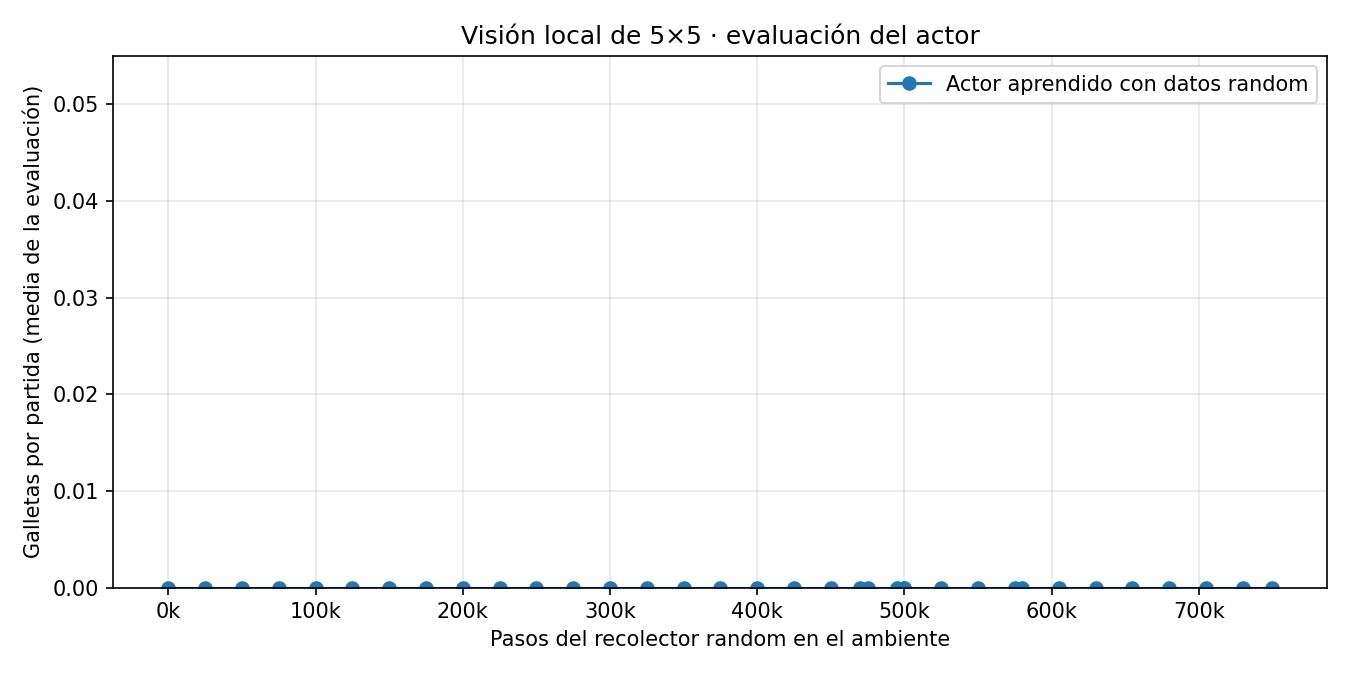

In [7]:
import json
from pathlib import Path

carpeta = Path(LOGDIR)
archivo_estado = carpeta / "status.json"
if archivo_estado.exists():
    estado = json.loads(archivo_estado.read_text())
    print(f"Checkpoint guardado: paso {estado['step']:,} de {estado['steps']:,}")
    print("Guardado:", estado.get("saved_at", "sin fecha"))
else:
    print("Todavía no hay un checkpoint guardado en esta carpeta.")

filas = []
archivo_metricas = carpeta / "metrics.jsonl"
if archivo_metricas.exists():
    for linea in archivo_metricas.read_text().splitlines():
        try:
            filas.append(json.loads(linea))
        except json.JSONDecodeError:
            pass
puntos_eval = [(f["step"], f["episode/eval_score"]) for f in filas if "episode/eval_score" in f]
if puntos_eval:
    paso, galletas = puntos_eval[-1]
    print(f"Última evaluación del ACTOR APRENDIDO: {galletas:.2f} galletas por partida en el paso {paso:,}")
else:
    print("Todavía no hay evaluaciones del actor guardadas.")
print("Las galletas de episode/score son del recolector RANDOM; no miden el aprendizaje del actor.")

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import Image, display

if puntos_eval:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    pasos, galletas = zip(*puntos_eval)
    ax.plot(pasos, galletas, marker="o", label="Actor aprendido con datos random")
    ax.set_title("Visión local de 5×5 · evaluación del actor")
    ax.set_xlabel("Pasos del recolector random en el ambiente")
    ax.set_ylabel("Galletas por partida (media de la evaluación)")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _: f"{x / 1000:g}k"))
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    salida = Path(LOGDIR) / "evaluacion_actor.png"
    fig.savefig(salida, dpi=150)
    display(Image(str(salida)))
    plt.close(fig)


## 12. Ver al actor aprendido jugar

El video usa el actor aprendido del último checkpoint guardado, eligiendo su acción más probable, igual que en evaluación. Este video sirve para ver qué aprendió con datos random. El número de pasos entrenados aparece en su encabezado.

El video de recolección random está en `train_video` de TensorBoard. Para generar este video del actor, primero deben existir un checkpoint y sus dependencias instaladas.


In [8]:
SEMILLA_EPISODIO = 0
VIDEO = f"{LOGDIR}/agente_episodio{SEMILLA_EPISODIO}.mp4"

!cd /content/r2dreamer-cookie && .venv/bin/python watch.py --logdir "{LOGDIR}" --out "{VIDEO}" \
    --seed {SEMILLA_EPISODIO} 2>&1 | tail -n 1

from IPython.display import Video
Video(VIDEO, embed=True, width=760)

816 pasos, 0 galletas. Video en /content/drive/MyDrive/galleta/semana22/cookie_partial_hall5_view5_s0_random/agente_episodio0.mp4
